In [1]:
import numpy as np
import pandas as pd
import gzip
import matplotlib.pyplot as plt

In [2]:
def readtraj(filename,atomNum):
    pos = []
    with gzip.open(filename,'rt') as f:
        while True:
            line = f.readline()
            if not line:
                break
            else:
                if 'ATOMS id type x y z ix iy iz' in line:
                    xyzs = []
                    for i in range(atomNum):
                        line = f.readline()
                        xyzs.append([float(x) for x in line.split()[2:5]])

                    pos.append(xyzs)

    pos = np.array(pos)
    return pos

In [3]:
def frac_pair(xyzs, cutoff,nHB=14):
    hb_frac = []
    for frame,xyz in enumerate(xyzs):
        vecs = xyz[1:28:2,:] - xyz[29:56:2,:]
        #print(vecs.shape)
        count = 0
        for i in range(vecs.shape[0]):
            d = np.linalg.norm(vecs[i,:])
            #print(frame,i,d)
            if d > cutoff:
                count +=1
        hb_frac.append(count/nHB)

    hb_frac = np.array(hb_frac)
    return np.mean(hb_frac)
        

In [4]:
f1 = '../temper.250.00.lammpstrj.gz'
pos1 = readtraj(f1,56)

In [5]:
pos1.shape

(450, 56, 3)

In [6]:
frac1 = frac_pair(pos1, 9.5)
frac1

0.006349206349206348

250.0 0.006349206349206348
254.79 0.008730158730158729
259.66 0.007777777777777777
264.63 0.009682539682539681
269.7 0.010476190476190474
274.86 0.015396825396825395
280.12 0.010952380952380953
285.48 0.018730158730158725
290.95 0.031111111111111107
296.52 0.03047619047619047
302.19 0.05412698412698412
307.98 0.15238095238095237
313.87 0.2520634920634921
319.88 0.4858730158730159
326.01 0.6409523809523808
332.25 0.7847619047619047
338.61 0.8822222222222222
345.09 0.9407936507936507
351.69 0.9657142857142856
358.42 0.9874603174603174
365.29 0.984920634920635
372.28 0.999047619047619
379.4 0.9963492063492064
386.67 0.999047619047619
394.07 1.0
401.61 0.9988888888888889
409.3 1.0
417.13 0.998095238095238
425.12 0.9985714285714287
433.25 0.999047619047619


Text(0, 0.5, 'Fraction of melted states')

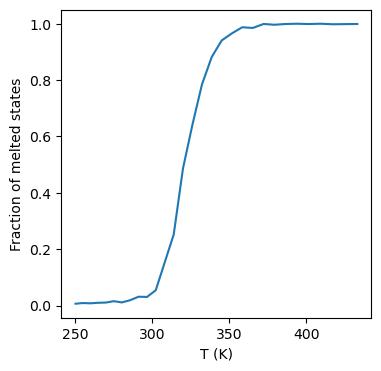

In [8]:
Ts = np.loadtxt('../Temps')

output = []

for T in Ts[:-2]:
    fname = '../temper.{:.2f}.lammpstrj.gz'.format(T)
    pos   = readtraj(fname,56)
    frac  = frac_pair(pos, 9.5)
    print(T, frac)
    output.append([T,frac])

output = np.array(output)

fig,ax = plt.subplots(figsize=(4,4))
ax.plot(output[:,0], output[:,1])
ax.set_xlabel('T (K)')
ax.set_ylabel('Fraction of melted states')